In [160]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import torchvision
import torchvision.datasets as datasets
from torchvision.transforms import ToTensor

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor() # scaling the pixel values from 0 -> 255 to 0 -> 1
)

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

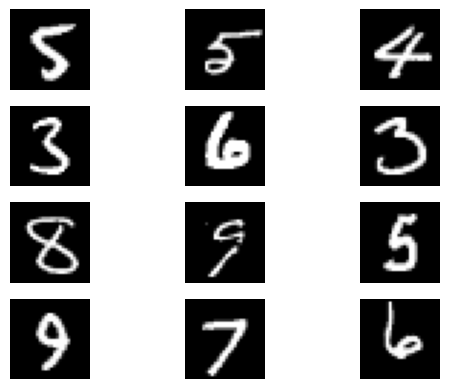

In [3]:
figure = plt.figure()
cols, rows = 3,4
for i in range (1, cols * rows+1):
    sample_index = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_index]
    figure.add_subplot(rows, cols, i)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [4]:
image, label = training_data[0]

print(image.shape)
print(label)
print(type(image))
print(type(label))
print(len(training_data))

torch.Size([1, 28, 28])
5
<class 'torch.Tensor'>
<class 'int'>
60000


In [5]:
image, label = test_data[0]

print(image.shape)
print(label)
print(type(image))
print(type(label))
print(len(test_data))

torch.Size([1, 28, 28])
7
<class 'torch.Tensor'>
<class 'int'>
10000


### Dataloader
A dataloader passes the data in "minibatches", so it prepares the data before training and randomly reorders the data before each training pass (epoch)

In [6]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

### Train CNN model
Below the following is defined:
- `in_channels`=1, as the image.shape gave [**1**,28,28], **1** is the channel
- `out_channels`=32, number of filters the model will learn, produce 32 feature maps
- `kernel_size`=3, tells the model to look at 3x3 region of the image at a time

The new shape `(32,26,26)` is defined below:
- **32**: is the number of output channels
- **26x26**: 
    - Kernel size = **3 × 3**
    - Stride = **1**
    - Padding = **0** (no padding)

    The output size is calculated as:

    $$
    \text{Output Size} =
    \frac{\text{Input Size} - \text{Kernel Size} + 2(\text{Padding})}{\text{Stride}} + 1
    $$

- `self.pool`, a pooling window of size 2x2 looks at a small section and takes the maximum value. This helps reduce the amount of data passed to the later layers, retians the strong features and reduce computation


In [7]:
class CNN(nn.Module): # nn.Module is pytorch's base class for neural networks

    def __init__(self):
        super().__init__()

        # convolational layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3
        ) # (32,26,26) new shape

        self.pool = nn.MaxPool2d(2,2) # (32, 13, 13)

        # 2nd convolational layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=5
        ) # (64, 9, 9)

        # call pool again then, the new shape would be (64, 4, 4)

        # flatten the shape, 64 * 4 * 4

        self.fcl1 = nn.Linear(64 * 4 * 4, 120)
        self.fcl2 = nn.Linear(120, 84)
        self.fcl3 = nn.Linear(84,10) # needs to have 10 here, as MNIST classification has 10 possible classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x)) # activation function, max(0, input value)
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

In [8]:
net = CNN() # creates an instance of the neural network defined above
loss_function = nn.CrossEntropyLoss() # tells us how wrong the model's predictions are
optimiser = optim.SGD(
    net.parameters(), 
    lr=0.001, 
    momentum=0.9
) # updates the models weights, uses the gradients calculated from the loss to update the weights

In [9]:
torch.save(net.state_dict(), 'trained_net.pth')

In [10]:
net = CNN()
net.load_state_dict(torch.load('trained_net.pth'))

<All keys matched successfully>

In [11]:
correct = 0 # how many are correct
total = 0 # how many were tested

net.eval() # tells pytorch that the model is being tested not trained

# no gradient updates needed as we are testing the model now
with torch.no_grad():
    for data in test_dataloader:
        images, labels = data # test images and correct answers
        outputs = net(images)
        # we only care about the index, torch.max(..) retruns 2 things, maximun value and the index 
        _, predicted = torch.max(outputs, 1) # find the maximum across the 10 class outputs 
        total += labels.size(0) 
        correct += (predicted == labels).sum().item()

accuracy = 100* correct / total

print(f'Accuracy: {accuracy}%')

Accuracy: 11.96%


Predicted: 5
Actual: 7


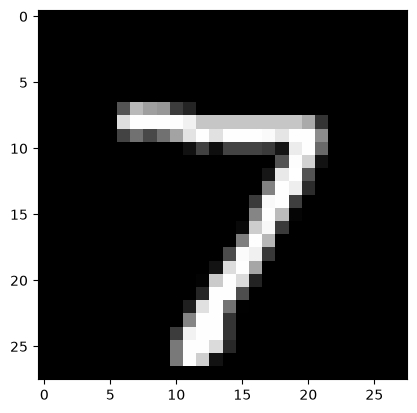

In [12]:
image = image.unsqueeze(0) # changes the shape to [batch, channels, height, width] -> [1,1,28,28]

net.eval()

with torch.no_grad():
    output = net(image)
    _,predicted = torch.max(output,1)

print("Predicted:", predicted.item())
print("Actual:", label)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

### Train Multi Layer Perceptron (MLP) model

In [13]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        # flatten layer
        # self.flatten = nn.flatten() # input [1,28,28] flattened input 1x28x28 = 784
        
        # define linear layers
        self.fcl1 = nn.Linear(784,128)
        self.fcl2 = nn.Linear(128,64)
        self.fcl3 = nn.Linear(64, 10)

    def forward(self,x):
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

In [14]:
model = MLP()
loss_function = nn.CrossEntropyLoss()
optimiser = optim.SGD(
    model.parameters(), 
    lr=0.001, 
    momentum=0.9
) 

In [15]:
torch.save(model.state_dict(), 'trained_mlp.pth')

In [16]:
model = MLP()
model.load_state_dict(torch.load('trained_mlp.pth'))

<All keys matched successfully>

In [17]:
# test the model
correct = 0
total = 0

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data

        outputs = model(images)

        # find the max in the outputs
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0) 
        correct += (predicted == labels).sum().item()

accuracy = 100* correct / total

print(f'Accuracy: {accuracy}%')

Accuracy: 5.76%


Predicted: 2
Actual: 7


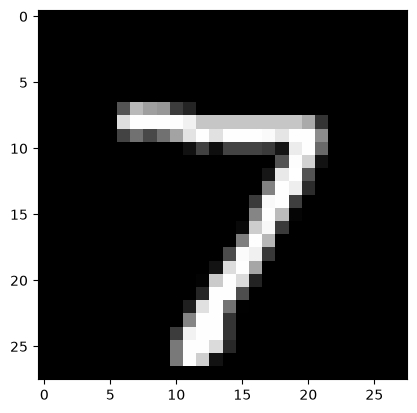

Predicted: 3
Actual: 2


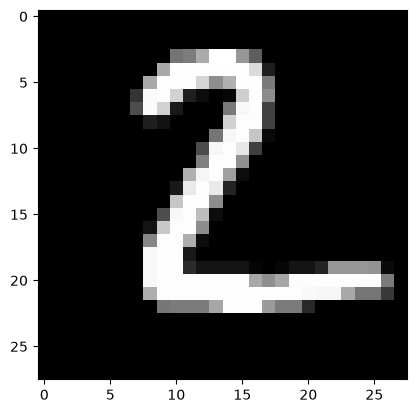

Predicted: 2
Actual: 1


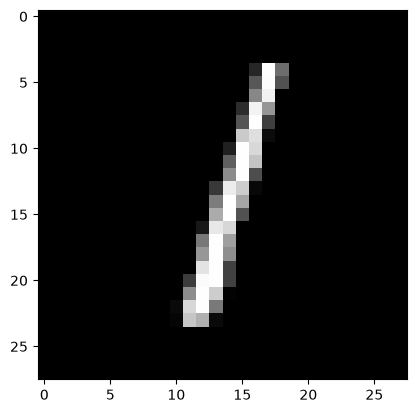

Predicted: 2
Actual: 0


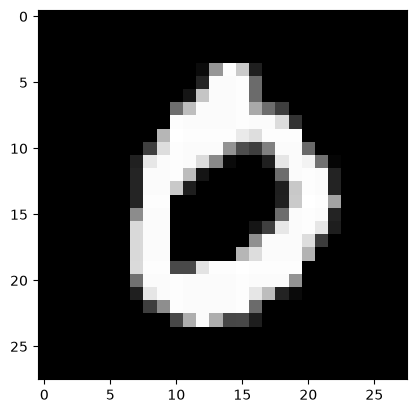

Predicted: 2
Actual: 4


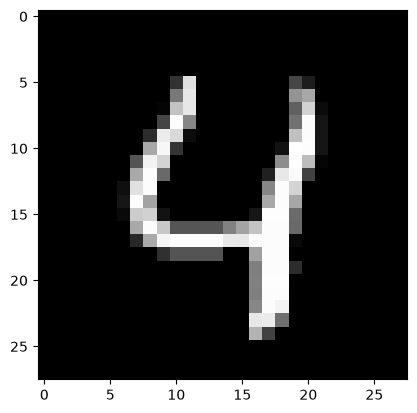

Predicted: 2
Actual: 1


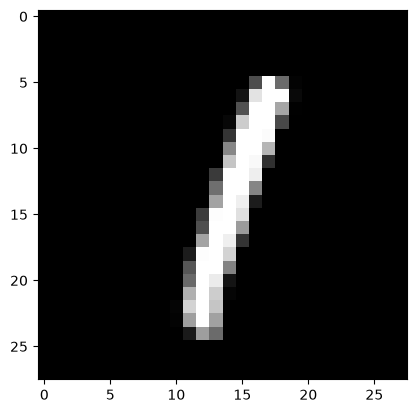

Predicted: 3
Actual: 4


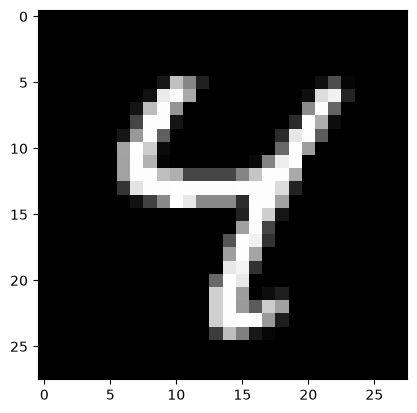

Predicted: 3
Actual: 9


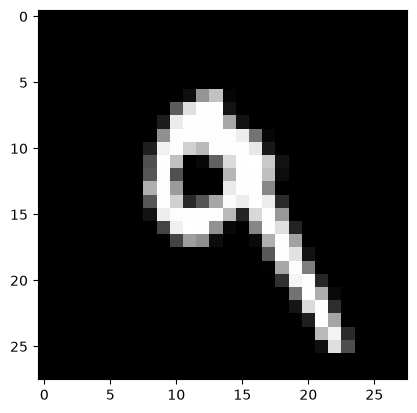

Predicted: 2
Actual: 5


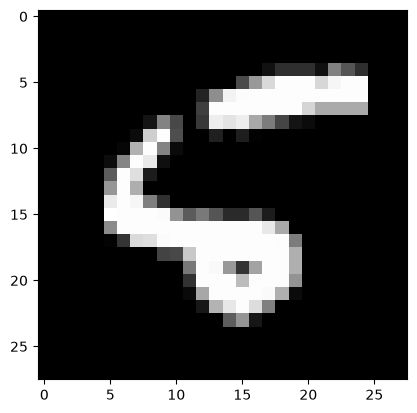

Predicted: 3
Actual: 9


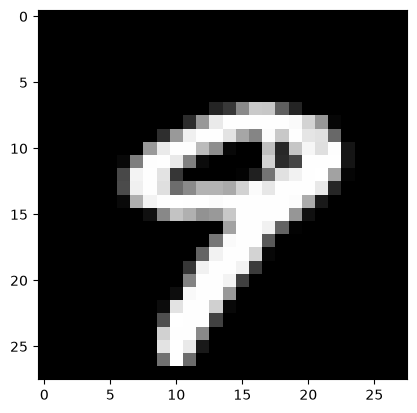

In [18]:
#image = image.unsqueeze(0) # changes the shape to [batch, channels, height, width] -> [1,1,28,28]

model.eval()

for i in range(10):
    image, label = test_data[i]
    with torch.no_grad():
        output = model(image.unsqueeze(0))
        _,predicted = torch.max(output,1)
    
    print("Predicted:", predicted.item())
    print("Actual:", label)
    
    plt.imshow(image.squeeze(), cmap="gray")
    plt.show()

## Autoencoders

Useful resources
- https://devshahs.medium.com/build-an-autoencoder-with-me-b784cabd7e70
- https://medium.com/@syed_hasan/autoencoders-theory-pytorch-implementation-a2e72f6f7cb7

In [19]:
df = pd.read_csv("../data/NF-UNSW-NB15-v2.csv")
df.head()

,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,59.166.0.5,1305,149.171.126.8,21,6,1.0,9,1,193,3,...,0,7240,0,0,0,0,0,331.0,0,Benign
1,59.166.0.5,1305,149.171.126.8,21,6,1.0,261,5,469,7,...,8688,8688,18944,74,0,0,0,230.0,0,Benign
2,59.166.0.5,1305,149.171.126.8,21,6,1.0,481,9,750,11,...,10136,10136,33792,132,0,0,0,229.0,0,Benign
3,59.166.0.5,1305,149.171.126.8,21,6,1.0,701,13,1054,15,...,11584,11584,48640,190,0,0,0,125.0,0,Benign
4,59.166.0.5,1305,149.171.126.8,21,6,1.0,1031,19,1474,21,...,14480,13032,64256,251,0,0,0,230.0,0,Benign


In [20]:
df.duplicated()

0          False
1          False
2          False
3          False
4          False
           ...  
2390270    False
2390271    False
2390272    False
2390273    False
2390274    False
Length: 2390275, dtype: bool

In [21]:
df.isnull().values.any()

np.False_

In [22]:
print(df.dtypes)

IPV4_SRC_ADDR                      str
L4_SRC_PORT                      int64
IPV4_DST_ADDR                      str
L4_DST_PORT                      int64
PROTOCOL                         int64
L7_PROTO                       float64
IN_BYTES                         int64
IN_PKTS                          int64
OUT_BYTES                        int64
OUT_PKTS                         int64
TCP_FLAGS                        int64
CLIENT_TCP_FLAGS                 int64
SERVER_TCP_FLAGS                 int64
FLOW_DURATION_MILLISECONDS       int64
DURATION_IN                      int64
DURATION_OUT                     int64
MIN_TTL                          int64
MAX_TTL                          int64
LONGEST_FLOW_PKT                 int64
SHORTEST_FLOW_PKT                int64
MIN_IP_PKT_LEN                   int64
MAX_IP_PKT_LEN                   int64
SRC_TO_DST_SECOND_BYTES        float64
DST_TO_SRC_SECOND_BYTES        float64
RETRANSMITTED_IN_BYTES           int64
RETRANSMITTED_IN_PKTS    

In [23]:
df = df.drop(columns=["IPV4_SRC_ADDR", "IPV4_DST_ADDR"])

In [24]:
print(df.shape)
print(df.columns)

(2390275, 43)
Index(['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES',
       'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS',
       'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN',
       'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT',
       'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN',
       'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES',
       'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
       'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS',
       'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
       'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
       'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
       'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT',
       'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE',
       'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack'],
      dtype='str')


For Autoencoder we don't want to train the model with the attacks so this should be removed from the train dataset

In [25]:
# split dataset into train and test
benign_df = df[df["Attack"] == "Benign"]
attack_df = df[df["Attack"] != "Benign"]

print(benign_df.shape)
print(attack_df.shape)

(2295222, 43)
(95053, 43)


In [26]:
# Test split
benign_train, benign_test = train_test_split(benign_df,test_size=0.2, random_state=42)

print(benign_train.shape)
print(benign_test.shape)

(1836177, 43)
(459045, 43)


In [27]:
test_df = pd.concat([attack_df, benign_test], ignore_index=True)
print(test_df.shape)

(554098, 43)


In [28]:
drop_columns = [
    "Label",
    "Attack"
]


X_train = benign_train.drop(columns=drop_columns)

y_test = test_df["Label"]
X_test = test_df.drop(columns=drop_columns)

In [29]:
print(X_train.shape)

(1836177, 41)


### Scaling
Transforms the numbers so they are on a more comparable scale, it changes the representation of the number
$$x_{\text{scaled}} = \frac{x - \text{mean}}{\text{standard deviation}}$$


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

In [31]:
X_train_tensor = torch.tensor(X_train_scaled,  dtype=torch.float32)
X_train_tensor.size()

torch.Size([1836177, 41])

In [32]:
X_test_scaled = scaler.transform(X_test) # use teh parameter learned from training 

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)  #nn.Linear uses torch.float32 but the numpy dtype is float.64
X_test_tensor.size()

torch.Size([554098, 41])

In [33]:
# split into batches
train_dataset = TensorDataset(X_train_tensor,)

train_dataloader_ae = DataLoader(train_dataset, batch_size=256, shuffle=True)

Teach the autoencoder what normal traffic looks like and try and reduce the reconstruction loss

- Hidden layer can be either fully connected (dense) or convulational layers
- The final hidden layer is a latent space representation
- Autoencoders operate one row at a time

In [34]:
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(41, 64),
            nn.ReLU(),
            nn.Linear(64,32),
            nn.ReLU(),
            nn.Linear(32,16),
            nn.ReLU()
            
        )

        self.decoder = nn.Sequential(
            nn.Linear(16,32),
            nn.ReLU(),
            nn.Linear(32,64),
            nn.ReLU(),
            nn.Linear(64,41),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)

        return x

In [35]:
autoencoder = Autoencoder()
loss_function = nn.MSELoss() # reconstruction loss
optimiser = optim.Adam(
    autoencoder.parameters(), 
    lr=0.001, 
)

Training epoch 0 ...
Loss: 0.6010
Training epoch 1 ...
Loss: 0.5707
Training epoch 2 ...
Loss: 0.5749
Training epoch 3 ...
Loss: 0.5774
Training epoch 4 ...
Loss: 0.5448
Training epoch 5 ...
Loss: 0.5378
Training epoch 6 ...
Loss: 0.5377
Training epoch 7 ...
Loss: 0.5362
Training epoch 8 ...
Loss: 0.5337
Training epoch 9 ...
Loss: 0.5152
Training epoch 10 ...
Loss: 0.5148
Training epoch 11 ...
Loss: 0.5145
Training epoch 12 ...
Loss: 0.5171
Training epoch 13 ...
Loss: 0.5213
Training epoch 14 ...
Loss: 0.5132
Training epoch 15 ...
Loss: 0.5160
Training epoch 16 ...
Loss: 0.5118
Training epoch 17 ...
Loss: 0.5012
Training epoch 18 ...
Loss: 0.5022
Training epoch 19 ...
Loss: 0.4938


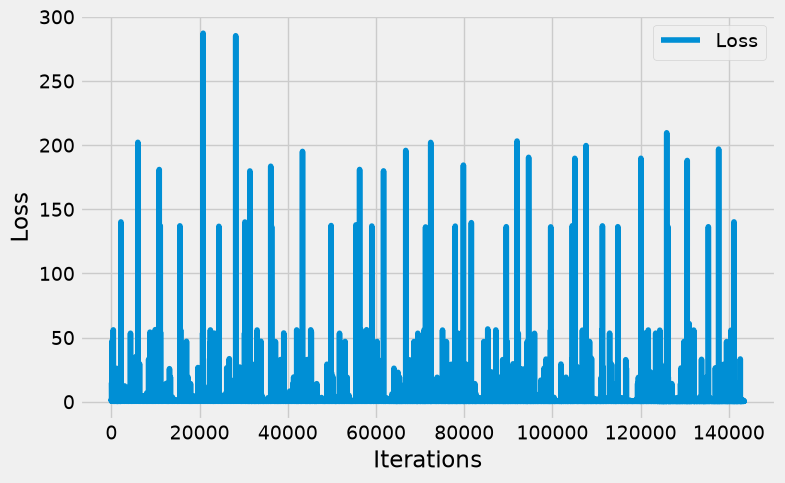

In [36]:
# train the model
epochs = 20
losses = []

for epoch in range(20):
    print(f"Training epoch {epoch} ...")

    running_loss = 0.0

    for (inputs,) in train_dataloader_ae:
        
        optimiser.zero_grad()

        reconstructed=autoencoder(inputs)

        loss = loss_function(reconstructed,inputs)
        loss.backward()
        optimiser.step()

        running_loss +=loss.item()

        losses.append(loss.item())
        
    print(f'Loss: {running_loss / len(train_dataloader_ae):.4f}')

plt.style.use('fivethirtyeight')
plt.figure(figsize=(8, 5))
plt.plot(losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [53]:
torch.save(autoencoder.state_dict(), 'trained_autoencoder.pth')

In [54]:
autoencoder_model = Autoencoder()
autoencoder_model.load_state_dict(torch.load('trained_autoencoder.pth'))

<All keys matched successfully>

In [55]:
# need to look at the reconstruction loss

autoencoder.eval()

with torch.no_grad():
    reconstructed = autoencoder(X_test_tensor)

print("Original shape:", X_test_tensor.shape)
print("Reconstructed shape:", reconstructed.shape)

Original shape: torch.Size([554098, 41])
Reconstructed shape: torch.Size([554098, 41])


low reconstruction error = normal traffic
high reconstruction error = less like normal traffic learned 

In [56]:
errors = torch.mean(
    (X_test_tensor - reconstructed) ** 2,
    dim=1
)

print(errors.shape)

torch.Size([554098])


In [57]:
print(errors[:20])

tensor([ 9.0791,  9.0791,  9.1632, 10.5308,  9.1544,  9.1550, 25.2820, 17.4540,
        17.4540, 17.4540, 17.4540, 17.4540, 17.4540, 10.2812, 10.2812, 10.2812,
        17.4884, 17.4884, 17.4884, 17.4884])


In [68]:
benign_errors = errors[y_test.to_numpy() == 0]
attack_errors = errors[y_test.to_numpy() == 1]

In [69]:
print("Benign:", benign_errors.shape)
print("Attack:", attack_errors.shape)

Benign: torch.Size([459045])
Attack: torch.Size([95053])


In [70]:
print(test_df.groupby(["Label","Attack"]).size())

Label  Attack        
0      Benign            459045
1      Analysis            2299
       Backdoor            2169
       DoS                 5794
       Exploits           31551
       Fuzzers            22310
       Generic            16560
       Reconnaissance     12779
       Shellcode           1427
       Worms                164
dtype: int64


In [72]:
print("Benign mean error", benign_errors.mean().item())
print("Attack mean error", attack_errors.mean().item())

print("Benign median error:", benign_errors.median().item())
print("Attack median error:", attack_errors.median().item())

Benign mean error 0.4421822428703308
Attack mean error 58.55622100830078
Benign median error: 0.22270983457565308
Attack median error: 9.142844200134277


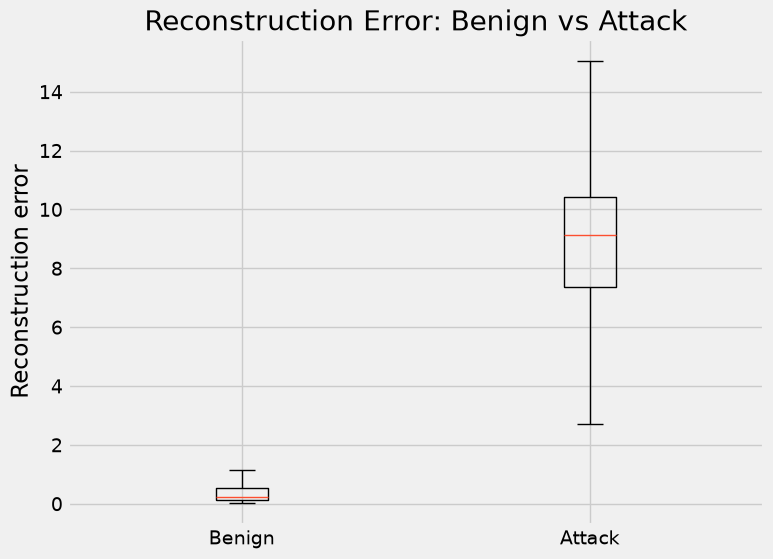

In [115]:
plt.figure(figsize=(8, 6))

plt.boxplot(
    [benign_np, attack_np],
    tick_labels=["Benign", "Attack"],
    showfliers=False
)

plt.ylabel("Reconstruction error")
plt.title("Reconstruction Error: Benign vs Attack")

plt.show()

In [176]:
# find what the best threshold is 
errors_np = errors.detach().cpu().numpy()
thresholds = np.linspace(errors.min().item(), errors.max().item(), 100)

precision, recall, thresholds = precision_recall_curve(y_test, errors_np)

precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / (precision + recall)

best_idx = np.argmax(f1)
best_threshold = thresholds[best_idx]
print("Best threshold:", best_threshold)

Best threshold: 9.008787


In [187]:
threshold = 0.6

predicted_labels = (errors > threshold).int()

cr = classification_report(
    y_test,
    predicted_labels.numpy(),
    target_names=["Benign","Attack"]
)

print(cr)

              precision    recall  f1-score   support

      Benign       0.95      0.84      0.89    459045
      Attack       0.51      0.79      0.62     95053

    accuracy                           0.84    554098
   macro avg       0.73      0.82      0.76    554098
weighted avg       0.88      0.84      0.85    554098



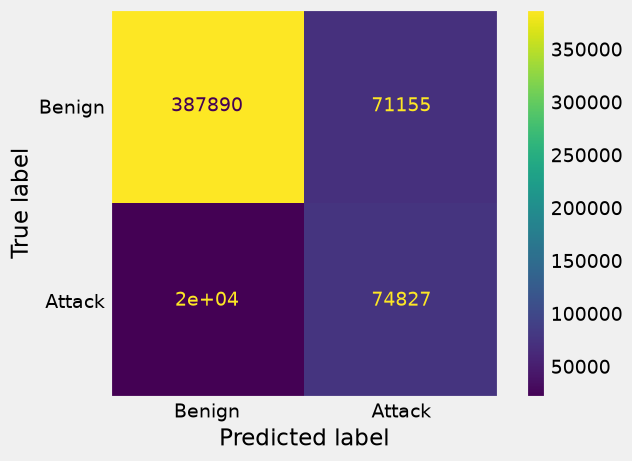

In [189]:
cm = confusion_matrix(y_test.to_numpy(), predicted_labels)
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Attack'])
display_cm.plot()
plt.grid(False)
plt.show()                                    